In [1]:
# set up the working environment

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re, random

import tensorflow as tf
from tensorflow.keras import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense, Bidirectional, Dropout
from tensorflow.keras.layers import Embedding, TextVectorization, StringLookup
from tensorflow.keras import losses


---

<br>


# Problem 1: Sentiment Analysis with Tweets

[Sentiment140 dataset](http://help.sentiment140.com/home), which contains 1.6 million tweets alongside their respective sentiment (0 for negative and 4 for positive.

Let's get started!

## Download and Explore the Data

In [2]:
# Command to download the data from Google Drive
# https://github.com/wkentaro/gdown

! gdown -O training_cleaned.csv 1p2J4BNxSWi7GqdtFKfySwmDlbEIovKtu

Downloading...
From: https://drive.google.com/uc?id=1p2J4BNxSWi7GqdtFKfySwmDlbEIovKtu
To: /content/training_cleaned.csv
100% 239M/239M [00:02<00:00, 106MB/s]


The dataset is provided in a csv file. Each row of this file contains the following values separated by commas:

- target: the polarity of the tweet (0 = negative, 4 = positive)

- ids: The id of the tweet

- date: the date of the tweet

- flag: The query. If there is no query, then this value is NO_QUERY.

- user: the user that tweeted

- text: the text of the tweet

Take a look at the first several examples:

In [3]:
sentiment_df = pd.read_csv("training_cleaned.csv", names=['target', 'id', 'datetime', 'flag', 'user', 'text'])
sentiment_df

,target,id,datetime,flag,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."
...,...,...,...,...,...,...
1599995,4,2193601966,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,AmandaMarie1028,Just woke up. Having no school is the best fee...
1599996,4,2193601969,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,TheWDBoards,TheWDB.com - Very cool to hear old Walt interv...
1599997,4,2193601991,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,bpbabe,Are you ready for your MoJo Makeover? Ask me f...
1599998,4,2193602064,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,tinydiamondz,Happy 38th Birthday to my boo of alll time!!! ...


<Br>

## Parse Raw Data

Now you need to read the data from the csv file and parse values in fields `target` and `text` into two separate lists.

The labels are originally encoded as strings ('0' representing negative and '4' representing positive). We change them to integers with 0 representing negative whereas 1 positive:

In [4]:
sentences = []
labels = []

for tweet in sentiment_df.to_dict(orient="records"):
    sentences.append(tweet['text'])
    labels.append(1 if tweet['target'] == 4 else 0)

print(f"This dataset contains {len(sentences)} examples\n")

print(f"Text of 2nd example should look like this:\n{sentences[1]}\n")
print(f"Text of 4th example should look like this:\n{sentences[3]}")

print(f"\nLabels of last 5 examples should look like this:\n{labels[-5:]}")

This dataset contains 1600000 examples

Text of 2nd example should look like this:
is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!

Text of 4th example should look like this:
my whole body feels itchy and like its on fire 

Labels of last 5 examples should look like this:
[1, 1, 1, 1, 1]


You might notice that this dataset contains a lot of examples. In order to keep a low execution time of this task, we will be using only 10% of the original data. The next cell does this while also randomnizing the data points that will be used:

In [5]:
# bundle the two lists into a single one
sentences_and_labels = list(zip(sentences, labels))

# perform random sampling
random.seed(42)
sentences_and_labels = random.sample(sentences_and_labels, int(len(sentences)*0.1))

# unpack back into separate lists
sentences, labels = zip(*sentences_and_labels)

print(f"There are {len(sentences)} sentences and {len(labels)} labels after random sampling\n")

There are 160000 sentences and 160000 labels after random sampling



## Training-validation Split

Now we perform a 90-10 split of the data into the training and validation sets:

In [6]:
train_size = int(len(sentences) * 0.9)
train_sentences = sentences[:train_size]
train_labels = labels[:train_size]
val_sentences = sentences[train_size:]
val_labels = labels[train_size:]

print(f"There are {len(train_sentences)} sentences for training.\n")
print(f"There are {len(train_labels)} labels for training.\n")
print(f"There are {len(val_sentences)} sentences for validation.\n")
print(f"There are {len(val_labels)} labels for validation.")

There are 144000 sentences for training.

There are 144000 labels for training.

There are 16000 sentences for validation.

There are 16000 labels for validation.


<br>

## Tokenization - Sequences, truncating and padding

Now it is time to begin the tokenization process.

To make things simple, we'll  use the high-level API `TextVectorzition` for this purpose.

One important decision we can make now is to set the maximum length of all sequences. Then, the `TextVetorziation` layer can handle truncation and padding automatically during tokenization.

> Note: truncating and padding seuqneces can also be deferred to a later stage by using different tools.   



In [7]:
# maximum length of all sequences
max_len = 16

# https://www.tensorflow.org/api_docs/python/tf/keras/layers/TextVectorization
preprocess = TextVectorization(output_sequence_length=max_len)
preprocess.adapt(train_sentences)

In [8]:
# get the vocabulary
vocab = preprocess.get_vocabulary()

# get the 20 most frequent tokens
print(vocab[:20])
# get the 20 least frequent tokens
print(vocab[-20:])

['', '[UNK]', 'i', 'to', 'the', 'a', 'my', 'and', 'you', 'is', 'it', 'in', 'for', 'of', 'im', 'on', 'me', 'so', 'have', 'that']
['021', '0200', '020', '01jun09', '012â\x82¬', '0100', '00where', '00ps', '00k', '00fieldsy', '008', '007', '0054am', '0051', '0045', '0029', '00202', '001sec', '0014', '0002']


> There are some weird tokens generated from the tokenization process.

>One remedy to this is to explicitly set a smaller vocabulary size using the `max_tokens` argument of the `TextVectorization` layer so as to remove a number of uncommon tokens. But for this relatively easy task, we just go with this rudimentary vocabulary without making any adjustments.


---

<br>

### Task 1

The `TextVectorzation` layer does not provide a way to access the word-to-index mapping it builds.  So, we're going to create it manually.

Please complete the following code to create a Python dictionary called `word_to_idx`, whose first 10 entries looks like the following:

```
{'': 0, '[UNK]': 1, 'i': 2, 'to': 3, 'the': 4, 'a': 5, 'my': 6, 'and': 7, 'you': 8, 'is': 9, ...}
 ```

In [9]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences


vocab_size = len(vocab)
max_length = max_len
trunc_type='post'
oov_tok = "<OOV>"

# Initialize the Tokenizer class
tokenizer = Tokenizer(num_words = vocab_size, oov_token = oov_tok)

# generate the word index dictionary for the training sentences
tokenizer.fit_on_texts(train_sentences)
word_to_idx = tokenizer.word_index


print(f"The vocabulary contains {vocab_size} words\n")
print(f"The out-of-vocabulary character is '{vocab[1]}'")
print(f"The padding character is '{vocab[0]}'")
print(f"\nthe index of word 'language' should be {word_to_idx['language']}")

The vocabulary contains 145794 words

The out-of-vocabulary character is '[UNK]'
The padding character is ''

the index of word 'language' should be 2462


***Expected Output:***

```
The vocabulary contains 145794 words

The out-of-vocabulary character is '[UNK]'
The padding character is ''

The index of word 'language' should be 2462
```


---

<br>

### Task 2

Complete the following code to perform word-to-index conversion for all sequences in `train_sentences` and `val_sentences`:


In [10]:
# train_ids =
# val_ids =

# generate and pad the training sequences
train_ids = preprocess(train_sentences)
val_ids = preprocess(val_sentences)

# also convert labels as numpy arrays
train_labels = np.array(train_labels)
val_labels = np.array(val_labels)


print(f"training sequences have a shape of: {train_ids.shape}\n")
print(f"validation sequences have a shape of: {val_ids.shape}\n")
print(train_labels.shape)
print(f"the first 5 sequences in the training set:\n{train_ids[:5]}")

training sequences have a shape of: (144000, 16)

validation sequences have a shape of: (16000, 16)

(144000,)
the first 5 sequences in the training set:
[[   161     15     70   3171   7512     12      4   4287     15    398
       6   4073  14321   1603   1804     16]
 [   118 100196    172    168 137401      9     95     90    363      0
       0      0      0      0      0      0]
 [130797    766      2     64    682     22      8     11     28     54
    7795  13635      9    534      8    419]
 [ 20561      2    274     82      7     82    147   1254    103   4879
       2    194     18      6    808      3]
 [     2    360   5389     80     13    758   3045    295     46      2
    1267      5    306   1966     13    196]]


***Expected Output:***

```
training sequences have a shape of: (144000, 16)

validation sequences have a shape of: (16000, 16)

the first 5 sequences in the training set:
[[   161     15     70   3171   7512     12      4   4287     15    398
       6   4073  14321   1603   1804     16]
 [   118 100196    172    168 137401      9     95     90    363      0
       0      0      0      0      0      0]
 [130797    766      2     64    682     22      8     11     28     54
    7795  13635      9    534      8    419]
 [ 20561      2    274     82      7     82    147   1254    103   4879
       2    194     18      6    808      3]
 [     2    360   5389     80     13    758   3045    295     46      2
    1267      5    306   1966     13    196]]

```



<br>

## Load Pre-trained Word Embeddings

To build the model, you will not be learning embeddings from your data but using  100 dimensional word vectors pre-trained with the [GloVe](https://nlp.stanford.edu/projects/glove/) algorithm on a 6-billion-token corpus.

In [11]:
# Python code to download and extract the word vector files
# https://www.tensorflow.org/api_docs/python/tf/keras/utils/get_file

pathname = tf.keras.utils.get_file("glove.6B.zip",
                                   origin="https://nlp.stanford.edu/data/glove.6B.zip",
                                   cache_dir='/content', cache_subdir='glove', extract=True)

# show the path to the downloaded file
print(f"\nthe place where the downloaded file is saved: {pathname}" )

862182613/862182613 [==============================] - 159s 0us/step

the place where the downloaded file is saved: /content/glove/glove.6B.zip


In [12]:
# System command to show the sizes of downloaded word vector files
!ls -lh glove

total 2.9G
-rw-r--r-- 1 root root 332M Nov 18 09:22 glove.6B.100d.txt
-rw-r--r-- 1 root root 662M Nov 18 09:22 glove.6B.200d.txt
-rw-r--r-- 1 root root 990M Nov 18 09:22 glove.6B.300d.txt
-rw-r--r-- 1 root root 164M Nov 18 09:22 glove.6B.50d.txt
-rw-r--r-- 1 root root 823M Nov 18 09:21 glove.6B.zip


There are 4 big plain text files (with the .txt extention).

The number before "d" in each file name indicates the dimensionality of word vectors stored in the corresponding file.

To see how a word vector is structured in these files, we load the first several lines from *glove.6B.100d.txt*:


In [13]:
with open("glove/glove.6B.100d.txt", "r") as f:
    for i in range(5):
        print(f.readline().strip('\n'))

the -0.038194 -0.24487 0.72812 -0.39961 0.083172 0.043953 -0.39141 0.3344 -0.57545 0.087459 0.28787 -0.06731 0.30906 -0.26384 -0.13231 -0.20757 0.33395 -0.33848 -0.31743 -0.48336 0.1464 -0.37304 0.34577 0.052041 0.44946 -0.46971 0.02628 -0.54155 -0.15518 -0.14107 -0.039722 0.28277 0.14393 0.23464 -0.31021 0.086173 0.20397 0.52624 0.17164 -0.082378 -0.71787 -0.41531 0.20335 -0.12763 0.41367 0.55187 0.57908 -0.33477 -0.36559 -0.54857 -0.062892 0.26584 0.30205 0.99775 -0.80481 -3.0243 0.01254 -0.36942 2.2167 0.72201 -0.24978 0.92136 0.034514 0.46745 1.1079 -0.19358 -0.074575 0.23353 -0.052062 -0.22044 0.057162 -0.15806 -0.30798 -0.41625 0.37972 0.15006 -0.53212 -0.2055 -1.2526 0.071624 0.70565 0.49744 -0.42063 0.26148 -1.538 -0.30223 -0.073438 -0.28312 0.37104 -0.25217 0.016215 -0.017099 -0.38984 0.87424 -0.72569 -0.51058 -0.52028 -0.1459 0.8278 0.27062
, -0.10767 0.11053 0.59812 -0.54361 0.67396 0.10663 0.038867 0.35481 0.06351 -0.094189 0.15786 -0.81665 0.14172 0.21939 0.58505 -0.52158 

So, each line starts with a word, which is followed by 100 floating-point numbers that collectively describe some important aspects of that word.

Run the following code to load them line by line and convert them into key-value pairs of a Python dictionary called `embeddings_index`:

In [14]:
# initialize an empty embeddings index dictionary
embeddings_index = {}

# read file and fill embeddings_index with its contents
with open('glove/glove.6B.100d.txt') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs

print(f'Found {len(embeddings_index)} word vectors.')
print(f"number of dimensions: {embeddings_index['hi'].shape}")

Found 400000 word vectors.
number of dimensions: (100,)


Let's take a look at the vector for the word ***language***:

In [15]:
test_word = 'language'

test_vector = embeddings_index[test_word]

print(f"Vector representation of word '{test_word}' looks like this:\n\n{test_vector}")

Vector representation of word 'language' looks like this:

[ 0.18519   0.34111   0.36097   0.27093  -0.031335  0.83923  -0.50534
 -0.80062   0.40695   0.82488  -0.98239  -0.6354   -0.21382   0.079889
 -0.29557   0.17075   0.17479  -0.74214  -0.2677    0.21074  -0.41795
  0.027713  0.71123   0.2063   -0.12266  -0.80088   0.22942   0.041037
 -0.56901   0.097472 -0.59139   1.0524   -0.66803  -0.70471   0.69757
 -0.11137  -0.27816   0.047361  0.020305 -0.184    -1.0254    0.11297
 -0.79547   0.41642  -0.2508   -0.3188    0.37044  -0.26873  -0.36185
 -0.096621 -0.029956  0.67308   0.53102   0.62816  -0.11507  -1.5524
 -0.30628  -0.4253    1.8887    0.3247    0.60202   0.81163  -0.46029
 -1.4061    0.80229   0.2019    0.60938   0.063545  0.21925  -0.043372
 -0.36648   0.61308   1.0207   -0.39014   0.1717    0.61272  -0.80342
  0.71295  -1.0938   -0.50546  -0.99668  -1.6701   -0.31804  -0.62934
 -2.0226    0.79405  -0.16994  -0.37627   0.57998   0.16643   0.1356
  0.0943   -0.24154   0.7123  

<br>

## Represent Words with Embeddings

For each word in the vocabulary, save its vector representation in a Numpy array:




In [16]:
# dimension of word vectors
embedding_dim = 100

# initialize a zero numpy array with the appropriate size
embedding_matrix = np.zeros((vocab_size, embedding_dim))

# iterate all of the words in the vocabulary
# if GloVe's representation exists for a word, save it in the embedding_matrix array
for word, i in word_to_idx.items():
    embedding_vector = embeddings_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

> Note: If a word in your vocabulary is not present in `embeddings_index`, the representation for that word is left as a row of 0s.

<br>

## Build a Model That Does Not Overfit

Now you can define a model that will handle the problem at hand while not overfitting.

### Task 3

Complete the following code to build and train an RNN model for this sentiment analysis task.

A couple of things to note / hints:

- Configure the Embedding layer to use pre-trained embeddings (`embeddings_initializer`).

- You can try different combinations of layers such as:

    - `Dropout`
    - `LSTM`    
    - `Bidirectional(LSTM)`

- The last two layers should be `Dense` layers.

- Include at least one `Dropout` layer to mitigate overfitting.

- The [`LSTM` layer](https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM) also provide two dropout options: `dropout` and `recurrent_dropout`. You can also experiment with them to see if they help mitigate overfitting. (E.g., set `dropout` to `0.4`).

- Try simpler architectures first to avoid long training time. Architectures that are able to solve this problem usually have around 2-4 layers (excluding the last two `Dense` ones and `Dropout` ones)

- The information about several key hyperparameters has been saved with variables `embedding_dim`, `max_len`, and `vocab_size`.



In [17]:
from tensorflow.keras import layers, Sequential

state_dim = 64
dense_dim = 32
model = Sequential([layers.Embedding(vocab_size, embedding_dim, input_length=max_length,
                                                 embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
                                                 trainable=False),
                    layers.Bidirectional(layers.LSTM(state_dim, return_sequences=True)),
                    layers.Dropout(0.4),
                    layers.Bidirectional(layers.LSTM(state_dim, return_sequences=True)),
                    layers.Dropout(0.4),
                    layers.Bidirectional(layers.LSTM(state_dim)),
                    layers.Dense(dense_dim, activation='relu'),
                    layers.Dense(1, activation='sigmoid')], name="multi_layer")


model.summary()

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# don't change the setting below
history = model.fit(train_ids, train_labels, batch_size=512, epochs=20, validation_data=(val_ids, val_labels))

Model: "multi_layer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 16, 100)           14579400  
                                                                 
 bidirectional (Bidirection  (None, 16, 128)           84480     
 al)                                                             
                                                                 
 dropout (Dropout)           (None, 16, 128)           0         
                                                                 
 bidirectional_1 (Bidirecti  (None, 16, 128)           98816     
 onal)                                                           
                                                                 
 dropout_1 (Dropout)         (None, 16, 128)           0         
                                                                 
 bidirectional_2 (Bidirecti  (None, 128)               

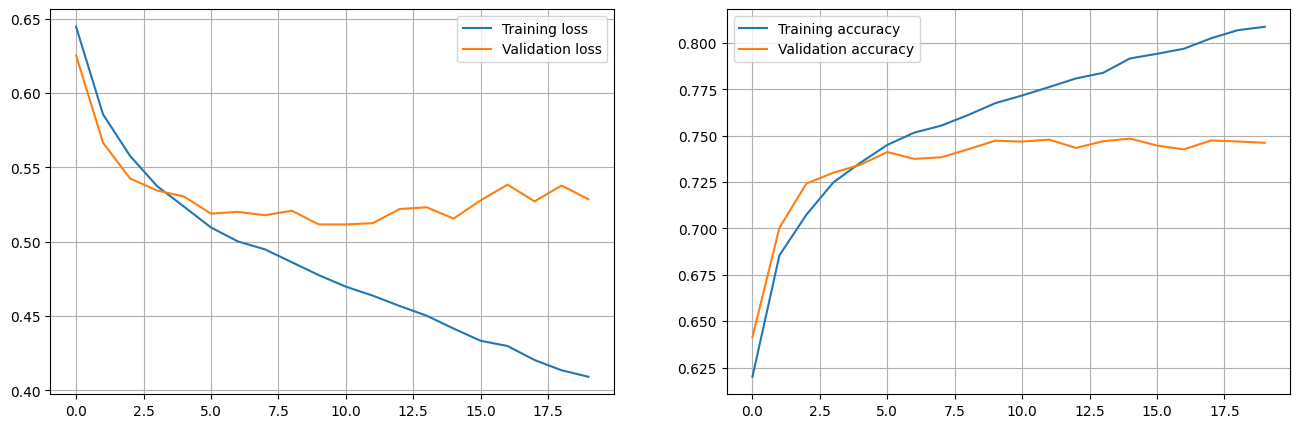

In [18]:
# plot the accuracy and loss history
metric_df = pd.DataFrame(history.history)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for metric, ax in zip(["loss", "accuracy"], axs):
    ax.plot(metric_df[metric], label=f'Training {metric}')
    ax.plot(metric_df['val_' + metric], label=f'Validation {metric}')
    ax.grid(True)
    ax.legend()

---

<br>

# Problem 2: Building a Character-level Language Model

For this part, you will be building a character-level language model and train it on *The Time Machine*, a science fiction novella to imitate its style of writing.

Note: This part is mainly exploration-oriented. Just read the instructions and run the given code to see how a language model can be implemented with TensorFlow.


## Download and Explore the Data

In [19]:
# download timemachine.txt

pathname = tf.keras.utils.get_file("timemachine.txt",
                                   origin="http://d2l-data.s3-accelerate.amazonaws.com/timemachine.txt",
                                   cache_dir='.', cache_subdir='')

178979/178979 [==============================] - 0s 0us/step


In [20]:
# read the data
with open("timemachine.txt") as f:
   raw_text = f.read()

# show the first 1000 characters
print(raw_text[:1000])

The Time Machine, by H. G. Wells [1898]




I


The Time Traveller (for so it will be convenient to speak of him)
was expounding a recondite matter to us. His grey eyes shone and
twinkled, and his usually pale face was flushed and animated. The
fire burned brightly, and the soft radiance of the incandescent
lights in the lilies of silver caught the bubbles that flashed and
passed in our glasses. Our chairs, being his patents, embraced and
caressed us rather than submitted to be sat upon, and there was that
luxurious after-dinner atmosphere when thought roams gracefully
free of the trammels of precision. And he put it to us in this
way--marking the points with a lean forefinger--as we sat and lazily
admired his earnestness over this new paradox (as we thought it)
and his fecundity.

'You must follow me carefully. I shall have to controvert one or two
ideas that are almost universally accepted. The geometry, for
instance, they taught you at school is founded on a misconception.'

'Is not

Next, to make things easy, we convert all alphabets in this giant string to lower case, and also remove all non-English-alphabet characters:


In [21]:
corpus = re.sub('[^A-Za-z]+', ' ', raw_text.lower())

# print the first 100 characters
print(corpus[:100])

the time machine by h g wells i the time traveller for so it will be convenient to speak of him was 


<br>

## Tokenizing Text

Because we are going to build a character-level language model, tokenization can be easily done by converting the `corpus` string to a Python list as follows:


In [22]:
print(list(corpus)[:20])

['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm', 'a', 'c', 'h', 'i', 'n', 'e', ' ', 'b', 'y', ' ']


Building the vocabulary can also be easily accomplished by using `set()` to remove duplicate characters from the `corpus` string:

In [23]:
vocab = sorted(set(corpus))
print(vocab)

[' ', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


Because now we don't need the full capacity of a `TextVectorization` layer, we opt for a more lightweight preprocessing layer called `StringLookup` to perform token-to-index conversion.


In [24]:
# https://www.tensorflow.org/api_docs/python/tf/keras/layers/StringLookup
ids_from_chars = StringLookup(vocabulary=vocab)

# use .get_vocabulary() to get the vocabulary
vocab = ids_from_chars.get_vocabulary()
vocab_size =len(vocab)

print(f"The vocabulary: {vocab}")

The vocabulary: ['[UNK]', ' ', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


> Note: the padding character is not necessary here, because later all sequences are forced to have the same length.





Now, you can use `ids_from_chars` to perform necessary preprocessing as follows:

In [25]:
# list(corpus[:20]) is the tokenization step
print(f"A list of tokens: {list(corpus[:20])}")

# ids_from_chars performs token-to-index conversion
ids_example = ids_from_chars(list(corpus[:20]))
print(f"A list of indices: {ids_example.numpy()}")

A list of tokens: ['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm', 'a', 'c', 'h', 'i', 'n', 'e', ' ', 'b', 'y', ' ']
A list of indices: [21  9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1]


To do index-to-token conversion, we need to define an inverting `StringLookup` layer:

In [26]:
chars_from_ids = StringLookup(vocabulary=vocab, invert=True)

print(f"A list of indices: {ids_example .numpy()}\n")

# chars_from_ids performs index-to-token conversion
# the output is in byte format
print(f"Recoverd tokens: {chars_from_ids(ids_example).numpy()}\n")


# if you want to see more readable output
# just decode the bytes to get the characters
for char in chars_from_ids(ids_example).numpy():
    print(char.decode('utf-8'), end='')

A list of indices: [21  9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1]

Recoverd tokens: [b't' b'h' b'e' b' ' b't' b'i' b'm' b'e' b' ' b'm' b'a' b'c' b'h' b'i'
 b'n' b'e' b' ' b'b' b'y' b' ']

the time machine by 

<br>

## Generate Training Data

Next, we'll generate the training data by dividing the text of this science fiction into fixed-length sequences of characters:


In [27]:
# set the length for training sequences
num_steps = 32

sequences = tf.constant([list(corpus[i:i+num_steps+1]) for i in range(len(corpus)-num_steps)])

# print the total number of sequences
print(f"training sequences have a shape of: {sequences.shape}\n")
# print the first 2 sequences
print(sequences[:2])

training sequences have a shape of: (173396, 33)

tf.Tensor(
[[b't' b'h' b'e' b' ' b't' b'i' b'm' b'e' b' ' b'm' b'a' b'c' b'h' b'i'
  b'n' b'e' b' ' b'b' b'y' b' ' b'h' b' ' b'g' b' ' b'w' b'e' b'l' b'l'
  b's' b' ' b'i' b' ' b't']
 [b'h' b'e' b' ' b't' b'i' b'm' b'e' b' ' b'm' b'a' b'c' b'h' b'i' b'n'
  b'e' b' ' b'b' b'y' b' ' b'h' b' ' b'g' b' ' b'w' b'e' b'l' b'l' b's'
  b' ' b'i' b' ' b't' b'h']], shape=(2, 33), dtype=string)


We then convert tokens to indices for all training sequences:

In [28]:
idx_sequences = ids_from_chars(sequences)

# print the first 2 sequences
print(idx_sequences[:2])

tf.Tensor(
[[21  9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1
  24  6 13 13 20  1 10  1 21]
 [ 9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24
   6 13 13 20  1 10  1 21  9]], shape=(2, 33), dtype=int64)


Here we define a helper function, which can quickly get us the human-readable text for these sequences of indices:

In [29]:
def text_from_ids(ids):
    return tf.strings.reduce_join(chars_from_ids(ids), axis=-1)

In [30]:
# decode the first 2 index sequences to what they actually represent
text_from_ids(idx_sequences[:2])

<tf.Tensor: shape=(2,), dtype=string, numpy=
array([b'the time machine by h g wells i t',
       b'he time machine by h g wells i th'], dtype=object)>


<br>

## Split Data into Features and Labels


Before feeding the data into the model, we need further split these fix-length sequences into inputs and labels.

Because the model we are building is a language model, which should generate one output token for each input token, we need to make sure, for each example, the input and the label have the same length.

We can achieve so by simply shifting the input tokens by one step so that the label at each input location is just the index of the next token.

In [31]:
# split the whole corpus
train_input = idx_sequences[:, :-1]
train_label = idx_sequences[:, 1:]

In [32]:
print(f"This is the input of the 1st example:\n{train_input[0, :]}")
print(f"This is the label of the 1st example:\n{train_label[0, :]}")
print(f"The actual content of the 1st example:")
print(f"input: '{text_from_ids(train_input[0, :]).numpy().decode()}'")
print(f"label: '{text_from_ids(train_label[0, :]).numpy().decode()}'\n")

print(f"This is the input of the 2nd example:\n{train_input[1, :]}")
print(f"This is the label of the 2nd example:\n{train_label[1, :]}")
print(f"The actual content of the 2nd example:")
print(f"input: '{text_from_ids(train_input[1, :]).numpy().decode()}'")
print(f"label: '{text_from_ids(train_label[1, :]).numpy().decode()}'\n")

This is the input of the 1st example:
[21  9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1
 24  6 13 13 20  1 10  1]
This is the label of the 1st example:
[ 9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24
  6 13 13 20  1 10  1 21]
The actual content of the 1st example:
input: 'the time machine by h g wells i '
label: 'he time machine by h g wells i t'

This is the input of the 2nd example:
[ 9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24
  6 13 13 20  1 10  1 21]
This is the label of the 2nd example:
[ 6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24  6
 13 13 20  1 10  1 21  9]
The actual content of the 2nd example:
input: 'he time machine by h g wells i t'
label: 'e time machine by h g wells i th'



## Use `tf.Dataset`

Next, we'll create a `tf.Dataset` for easily batching and shuffling data.

In [33]:
dataset = tf.data.Dataset.from_tensor_slices((idx_sequences[:, :-1], idx_sequences[:, 1:]))
dataset

<_TensorSliceDataset element_spec=(TensorSpec(shape=(32,), dtype=tf.int64, name=None), TensorSpec(shape=(32,), dtype=tf.int64, name=None))>

For example, we can quickly divide the training sequences into batches of 16 examples, and get the total number of batches you have:

In [34]:
print(f"No. of batches: {dataset.batch(16).cardinality() }")

No. of batches: 10838


We can easily change the way we batch the training examples:

In [35]:
# now divide the training sequences into batches of size 4, and take the 1st batch
for input_batch, label_batch in dataset.batch(4).take(1):
    # print the inputs and labels separately for the 4 examples
    print(input_batch, "\n")
    print(label_batch)

tf.Tensor(
[[21  9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1
  24  6 13 13 20  1 10  1]
 [ 9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24
   6 13 13 20  1 10  1 21]
 [ 6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24  6
  13 13 20  1 10  1 21  9]
 [ 1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24  6 13
  13 20  1 10  1 21  9  6]], shape=(4, 32), dtype=int64) 

tf.Tensor(
[[ 9  6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24
   6 13 13 20  1 10  1 21]
 [ 6  1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24  6
  13 13 20  1 10  1 21  9]
 [ 1 21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24  6 13
  13 20  1 10  1 21  9  6]
 [21 10 14  6  1 14  2  4  9 10 15  6  1  3 26  1  9  1  8  1 24  6 13 13
  20  1 10  1 21  9  6  1]], shape=(4, 32), dtype=int64)


The actual dataset specification we'll use is as follows:

In [36]:
buffer_size = 20000
batch_size = 1024

ds = dataset.shuffle(buffer_size).batch(batch_size).prefetch(buffer_size=tf.data.AUTOTUNE)

## Create the Model

Because a language model behaves differently in training (generating the outputs for all time steps of each input sequence) and prediction (generating the output only for one time step at a time), we cannot simply use the `Sequential` API to build the model.

Instead, we need to use the subclassing API to do finer customization of its generative behavior.

In [37]:
class MyRNNLM(Model):

    def __init__(self, num_hiddens, vocab_size, embedding_dim):
        super().__init__()

        # initialize all layers we want to use
        self.embedding = Embedding(vocab_size, embedding_dim)
        self.rnn = LSTM(num_hiddens, return_sequences=True,
                        return_state=True)
        self.linear = Dense(vocab_size)

    # the call function defines all computations required for a forward pass
    # it uses the functional API
    def call(self, inputs, initial_state=None, return_state=False, training=False):

        outputs = self.embedding(inputs, training=training)

        # states is a Python list that contains the hidden and cell states (with the hidden state preceding the cell state)
        # output from the last time step
        # we have it as the result of calling self.rnn() because we set return_state=True above
        outputs, *states = self.rnn(outputs, initial_state=initial_state, training=training)
        outputs = self.linear(outputs, training=training)

        if return_state:
           return outputs, states    # states is a list of 2 tensors, each of shape (batch_size, num_hiddens)
        else:
            return outputs

Next, we define several key hyperparameters and instantiate the model:

In [38]:
# The embedding dimension
embedding_dim = 128

# number of units used for both the hidden state and the cell state
num_hiddens = 256

# recall: vocab_size equals 28

model = MyRNNLM(num_hiddens, vocab_size, embedding_dim)

In [39]:
# pass the first 2 batches through the model to check the dimensionality of model output
for input_batch, label_batch in ds.take(2):
    batch_predictions = model(input_batch)
    print(batch_predictions.shape, "# (batch_size, sequence_length, vocab_size)")

(1024, 32, 28) # (batch_size, sequence_length, vocab_size)
(1024, 32, 28) # (batch_size, sequence_length, vocab_size)


It works as intended. We can print the summary of the model architecture as usual:


In [40]:
model.summary()

Model: "my_rnnlm"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     multiple                  3584      
                                                                 
 lstm_3 (LSTM)               multiple                  394240    
                                                                 
 dense_2 (Dense)             multiple                  7196      
                                                                 
Total params: 405020 (1.55 MB)
Trainable params: 405020 (1.55 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


---

<br>

### Task 4

Explain why the model has a specific number of parameters for each layer shown in the model summary.

>  Double click this cell to enter your answer. You may want to use LaTex to edit your formulas (reference: https://ashki23.github.io/markdown-latex.html#latex. Note: use of LaTex is not required).



**Embedding Layer**
> Embedding Layer = vocab_size * embedding_dim
Embedding Layer

= 28 * 128 = 3584


**LSTM Layer**
> LSTM Layer = 4 * ((embedding_dim + num_hiddens) * num_hiddens + num_hiddens)

= 4 * ((128 + 256) * 256 + 256)

= 4 * (384 * 256 + 256)

= 4 *  98560

= 394240

Explain:

**Dense Layer**
> Dense Layer = vocab_size * hidden_num + vocab_size

= 28 * 256 + 28 = 7196

**Total parameter** = Embedding Layer + LSTM + Dense = 405020






## Train the Model

The steps to train the model are standard:

In [41]:
loss = losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer='adam', loss=loss, metrics=['accuracy'])

history = model.fit(ds, epochs=50)

Epoch 1/50
170/170 [==============================] - 8s 34ms/step - loss: 2.4833 - accuracy: 0.2834
Epoch 2/50
170/170 [==============================] - 6s 33ms/step - loss: 1.9206 - accuracy: 0.4142
Epoch 3/50
170/170 [==============================] - 6s 36ms/step - loss: 1.6762 - accuracy: 0.4883
Epoch 4/50
170/170 [==============================] - 6s 36ms/step - loss: 1.5199 - accuracy: 0.5336
Epoch 5/50
170/170 [==============================] - 7s 38ms/step - loss: 1.4140 - accuracy: 0.5639
Epoch 6/50
170/170 [==============================] - 6s 33ms/step - loss: 1.3369 - accuracy: 0.5859
Epoch 7/50
170/170 [==============================] - 6s 35ms/step - loss: 1.2763 - accuracy: 0.6028
Epoch 8/50
170/170 [==============================] - 6s 32ms/step - loss: 1.2263 - accuracy: 0.6171
Epoch 9/50
170/170 [==============================] - 6s 33ms/step - loss: 1.1819 - accuracy: 0.6303
Epoch 10/50
170/170 [==============================] - 6s 33ms/step - loss: 1.1422 - accura


<br>

## Generate Text


Each time we call the model to generate text, we pass in some text and an initial state.

In return, the model generates a prediction for the next character and its new state to be used to make the next prediction.

Then, we pass the prediction and state back in to continue generating text.

The following makes a single step prediction:

In [46]:
class Generator(tf.Module):
    def __init__(self, model, chars_to_ids, ids_to_chars, temperature=1.0):
        self.temperature = temperature
        self.model = model
        self.chars_from_ids = chars_from_ids
        self.ids_from_chars = ids_from_chars
        self.vocab_size = len(ids_from_chars.get_vocabulary())

        # create a mask to prevent "[UNK]" from being generated
        skip_ids = self.ids_from_chars(['[UNK]'])[:, None]
        sparse_mask = tf.SparseTensor(values=[-float('inf')] * len(skip_ids),
                                      indices=skip_ids,
                                      dense_shape=[self.vocab_size])
        self.prediction_mask = tf.sparse.to_dense(sparse_mask)

    def generate_one_step(self, inputs, max_num_preds=50, states=None):
        # split the input sequence into tokens
        input_chars = tf.strings.unicode_split(inputs, 'UTF-8')
        # do token-to-index conversion
        input_ids = self.ids_from_chars(input_chars).to_tensor()

        # feed the input into the model to generate both a one-step prediction
        # and the state to be used to make the next prediction
        predicted_logits, states = self.model(inputs=input_ids, initial_state=states, return_state=True)
        predicted_logits = predicted_logits[:, -1, :]
        predicted_logits = predicted_logits/self.temperature

        # prevent "[UNK]" from being generated by setting its logit to negative infinity
        predicted_logits = predicted_logits + self.prediction_mask

        # sample a token (actually the index of a token) based on predicted_logits
        predicted_ids = tf.random.categorical(predicted_logits, num_samples=1)
        predicted_ids = tf.squeeze(predicted_ids, axis=-1)

        # convert the sampled index to the character
        predicted_chars = self.chars_from_ids(predicted_ids)

        return predicted_chars, states

<br>

## See the Model in Action

After all the work above, it is time to see our model generating text.  

Run the cell below to generate the next 500 characters of a seed text (i.e., "*it has*")


In [45]:
# instantiate the prediction process
one_step_model = Generator(model, chars_from_ids, ids_from_chars)

# specify a seed text
prefix = 'it has'
next_char = tf.constant([prefix])
result = [next_char]
states = None

# start the generation process
for n in range(500):
    next_char, states = one_step_model.generate_one_step(next_char, states=states)
    result.append(next_char)

# join indivivdual characters to form a more readable string
tf.strings.join(result)

<tf.Tensor: shape=(1,), dtype=string, numpy=
array([b'it hasty these monaming which i wrung over and the thing i saw the water helped me it was even strange against gravious very high mrs watchett had waked by the merens of break ouger hiscover the time traveller was not she was yourage thither comes and the some of every box casting beach the sensation reminded me of my shoes was uniform up the risk was impertace however laughed the milling of the sky i made a model of eight hursunged soon in a number of serious people doorway as the huge reptilian brut'],
      dtype=object)>